# Report 24 -- Part I results, mechanisms and trust


Settings: N = 1000, K = 70 (Watts-Strogatz), T = 80, 40 voting rounds, 25 seeds per point.

# RQ1: Delegation dynamics

![](output/results_part1/figures/1_RQ1_delegation/all.png)

## Delegation cycles

![](output/results_part1/figures/4_Cycles/all_cycles.png)

Metrics (last 30 rounds of each run):

- **Cycles per round**: number of delegation cycles
- **Share of 2-cycles**: cycles with two members (i -> j, j -> i)
- **Feeding in (share)**: agents whose chain ends in a cycle without being part of it
- **Opinion-dist. ratio (2-cycles)**:

  $$\text{ratio} = \frac{\text{mean } |o_i - o_j| \text{ within 2-cycles}}{\text{mean } |o_i - o_{t(i)}| \text{ over all delegations } i \to t(i)}$$

  1 = members of a 2-cycle are as far apart as a typical delegation pair, < 1 = closer

Short:

- Opinion: almost only 2-cycles between similar agents (ratio ~0.6 falling to ~0.35), hardly anyone feeds in
- Power and trust: larger cycles, ratio ~1, most lost votes from agents feeding in

## Explanation: power

![](output/results_part1/figures/5_Mechanisms/pw_only_explanation.png)

Metrics:

- **Downhill step**: delegation to a neighbour with less voting power than the delegator (power of the previous round)
- **Chains with / without downhill step**: share of resolved chains containing at least one / no downhill step
- **Chain length with / no downhill step**: average length of these two kinds of chains

Short:

- Long chains needa downhill (or equal-power) step
- pw only: downhill chains vanish between 70 and 100 % -> cycles and lost votes collapse
- Long chains are the downhill ones (~4-4.4 steps) -> their disappearance causes the chain-length kink

# RQ2: Quality of representation

![](output/results_part1/figures/2_RQ2_representation/drift_delegators.png)

Metric:

- **Avg. ideological drift (delegators)**: mean |o_i - o_R(i)| between a delegator's opinion and the vote cast for it (lost votes excluded)
- Random benchmark: a delegator with a random representative has drift 1/3

Short:

- Opinion lowers drift right away: 0.33 -> 0.11 at 10 %, 0.04 at 100 %
- Power and trust stay at the random benchmark (~0.33): they change how many delegate, not how well they choose
- Combined: as soon as r_op > 0, drift stays low (~0.04-0.06) whatever r_pw and r_tr

# Understanding trust

Question: trust should let agents learn which neighbours represent them well, so delegator drift should fall below the random value 1/3. In RQ2 it does not. This section checks whether the trust signal or the choice rule is the reason.

**Trust signal.** After a voting round, every delegator $i$ compares its own opinion $o_i$ with the vote $v$ that was cast for it (the opinion of its chain's root), $d = |o_i - v|$:

$$s = \max\left(1 - \frac{d}{\theta},\ -1\right)$$

- $s = 1$ if the vote matches exactly ($d = 0$), $s = 0$ at $d = \theta$, negative beyond, never below $-1$ (lost vote: $s = -1$)
- $s$ only updates trust in the chosen neighbour: $\tau \leftarrow (1 - \lambda)\,\tau + \lambda\,(1 + s)$, so $s > 0$ pushes trust above the neutral 1 and $s < 0$ below it
- $\theta$ is the **neutral distance**: votes closer than $\theta$ are good news, votes farther away bad news

**Where 1/3 comes from.** Opinions are uniform on $[0, 1]$ and independent of the network, so a neighbour picked at random is at expected distance

$$E\,|o_i - o_j| = \int_0^1\!\!\int_0^1 |x - y|\,dx\,dy = \frac{1}{3}$$

1/3 is therefore the drift of a delegator who learns nothing. A useful signal should be about 0 at that distance, positive only for better-than-random delegates.

| | baseline $\theta = 0.5$ | $\theta = 1/3$ |
|---|---|---|
| signal | $s = 1 - 2d$ | $s = \max(1 - 3d,\ -1)$ |
| neutral at | $d = 0.5$ | $d = 1/3$ (random) |
| $s$ at random distance $d = 1/3$ | $+1/3$ | $0$ |
| mean $s$ for a random delegate | $+0.33$ | $+0.04$ |
| example $d = 0.1 / 0.3 / 0.5$ | $0.8 / 0.4 / 0$ | $0.7 / 0.1 / -0.5$ |

- With $\theta = 0.5$, even a random delegate gets positive signals on average: trust rises for whoever is chosen, close or not, so it reinforces habit rather than quality
- With $\theta = 1/3$, only delegates closer than random gain trust, worse ones lose it: the signal separates good from bad delegates

Variants (trust only, r_op = r_pw = 0):

| variant | change |
|---|---|
| baseline (theta = 0.5) | model as in the thesis |
| theta = 1/3 | only delegates closer than a random neighbour (1/3) are rewarded |
| slow forgetting (50 % / 20 VR) | neighbours not delegated to forget 50 % over 20 instead of 5 voting rounds |
| no forgetting | neighbours not delegated to keep their trust |

Metrics:

- **Avg. ideological drift (delegators)**: drift among delegating agents only, 1/3 = random choice
- **Most chosen neighbour**: per agent, how often it chose its most chosen neighbour over the run (= trust signals to that neighbour)
- **Mean trust by distance**: final trust tau toward neighbours with at least one signal, by opinion distance |o_i - o_j|

## K = 70, T = 80 (40 voting rounds)

![](output/trust_variants/figures/K70/outcomes.png)

![](output/trust_variants/figures/K70/signals_most_chosen.png)

![](output/trust_variants/figures/K70/tau_by_distance.png)

- Delegator drift stays at ~0.33 for every variant
- Most chosen neighbour: only ~2-3 of ~25 delegations
- Trust hardly falls with distance (tau ~1.01 close vs ~1.00 far)

## K = 70, T = 500 (500 voting rounds)

![](output/trust_variants/figures/K70_T500/outcomes.png)

![](output/trust_variants/figures/K70_T500/tau_by_distance.png)

- More signals barely help: only "no forgetting" lowers delegator drift (0.30 at 100 %)

## K = 10, T = 80 (40 voting rounds)

![](output/trust_variants/figures/K10/outcomes.png)

![](output/trust_variants/figures/K10/signals_most_chosen.png)

![](output/trust_variants/figures/K10/tau_by_distance.png)

- Fewer neighbours: most chosen neighbour gets ~5-6 delegations
- Learning becomes visible with no / slow forgetting (drift 0.29 / 0.30 at 100 %)

## K = 70, delegate to the best neighbour

A delegating agent always picks its most attractive neighbour instead of drawing one in proportion to A (ties broken at random).

![](output/trust_variants/figures/K70_greedy/outcomes.png)

![](output/trust_variants/figures/K70_greedy/tau_by_distance.png)

- Delegator drift drops to ~0.23-0.25, with theta = 1/3 to ~0.18-0.21
- -> the bottleneck is the proportional choice among 70 neighbours (trust factor capped at 2), not the trust signal

# RQ3: Concentration of voting power

![](output/results_part1/figures/3_RQ3_concentration/all_ws_vs_ba.png)

Metrics:

- **Top-5 % voting-power share**: share of the cast votes held by the 5 % most powerful agents
- **Agents needed for 50 % of power**: smallest share of agents that together cast half of the votes

Short:

- Solid = Watts-Strogatz, dashed = Barabasi-Albert (same N, K, r values; % scale calibrated on WS)
- BA concentrates power more under power responsiveness (top-5 % at 20 %: 0.54 vs 0.43, at saturation 0.75 vs 0.69); opinion and trust differ little

# Report 23: Part II calibration (r_ig, homophily, minority share)

Python version of `Report_23.Rmd`. Every result is saved twice under the same name:

```
output/report23/
  figures/<folder>/<name>.png
  tables/<folder>/<name>.csv      values behind the figure: mean, 95% CI and number of seeds per point
  timings.csv                     how long every step took
```

| folder | content |
|---|---|
| `1_Part1_carryover` | settings and the % -> r table carried over from Part I |
| `2_r_ig_calibration` | isolated r_ig sweep, r_ig ceiling and % -> r_ig table |
| `3_Homophily` | homophily levels 0.3-0.6 vs. maximum, across background levels |
| `4_Minority_share` | minority share 15-40 %, r_ig alone and all four r together |
| `5_Final_values` | final Part II settings |

In [1]:
import time

import jax
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

jax.config.update("jax_compilation_cache_dir", "data/jax_cache")  # compiled kernels survive kernel restarts
NOTEBOOK_START = time.perf_counter()

from liquid.batch import TIMINGS, cached, run_window_grid
from liquid.calibration import crossing
from thesis_helpers import GROUP_COLORS, Output, group_facet_plot, metric_grid_plot, palette, summarise, timed, timing_table

out = Output("output/report23")
F = dict(p1="1_Part1_carryover", rig="2_r_ig_calibration", hom="3_Homophily", share="4_Minority_share", final="5_Final_values")

## 1. Carried-over Part I calibration

In [2]:
N_SEEDS = 100
N, K, T, NV, C = 1000, 60, 80, 40, 0.5   # as Report_23.Rmd (K = 60); results_part1.ipynb uses the Python calibration K = 70
LAM = 1 - (1 - 0.5) ** (1 / 5)           # 50 % of the trust signal forgotten over 5 voting rounds
MINORITY_SHARE = 0.2
POLARISED_SPLIT = 0.5                    # polarised: minority ~ U[0, 0.5), majority ~ U[0.5, 1)
SEEDS = range(1, N_SEEDS + 1)
BASE = dict(N=N, K=K, network_type="ws", T=T, nv=NV, lam=LAM, c=C)

PCT_TABLE_P1 = pd.DataFrame({
    "pct": [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "r_op": [0.00, 13.17, 28.85, 48.58, 72.89, 109.53, 166.16, 243.11, 429.31, 910.23, 16384.00],
    "r_pw": [0.00, 0.05, 0.10, 0.15, 0.20, 0.32, 0.51, 1.07, 3.04, 6.59, 64.00],
    "r_tr": [0.00, 2.09, 3.99, 6.79, 9.76, 12.86, 15.97, 22.97, 30.01, 48.68, 128.00],
})


def r_from_pct_p1(dim, pct):
    return np.interp(pct, PCT_TABLE_P1["pct"], PCT_TABLE_P1[f"r_{dim}"])


def condition_columns(condition, target_h=np.nan):
    # random: uniform opinions, no shuffle | polarised: opinions split by group | homophilic: polarised + group-homophily shuffle
    # | non-polarised-homophily: uniform opinions + group-homophily shuffle
    condition, target_h = pd.Series(condition), pd.Series(target_h, index=pd.Series(condition).index)
    polarised = condition.isin(["polarised", "homophilic"])
    shuffled = condition.isin(["homophilic", "non-polarised-homophily"])
    return dict(minority_share=MINORITY_SHARE, opinion_split=np.where(polarised, POLARISED_SPLIT, np.nan),
                target_homophily=np.where(shuffled, target_h, np.nan))


out.table(PCT_TABLE_P1, F["p1"], "pct_to_r_part1")
out.table(pd.DataFrame({"setting": ["N", "network", "K", "p_rewire", "T", "n_voting_rounds", "lambda", "c", "minority share", "seeds"],
                        "value": [N, "ws", K, 0.05, T, NV, round(LAM, 4), C, MINORITY_SHARE, N_SEEDS]}), F["p1"], "settings")

,setting,value
0,N,1000
1,network,ws
2,K,60
3,p_rewire,0.05
4,T,80
5,n_voting_rounds,40
6,lambda,0.1294
7,c,0.5
8,minority share,0.2
9,seeds,100


## 2. r_ig calibration

r_ig swept alone (random condition, r_op = r_pw = r_tr = 0).

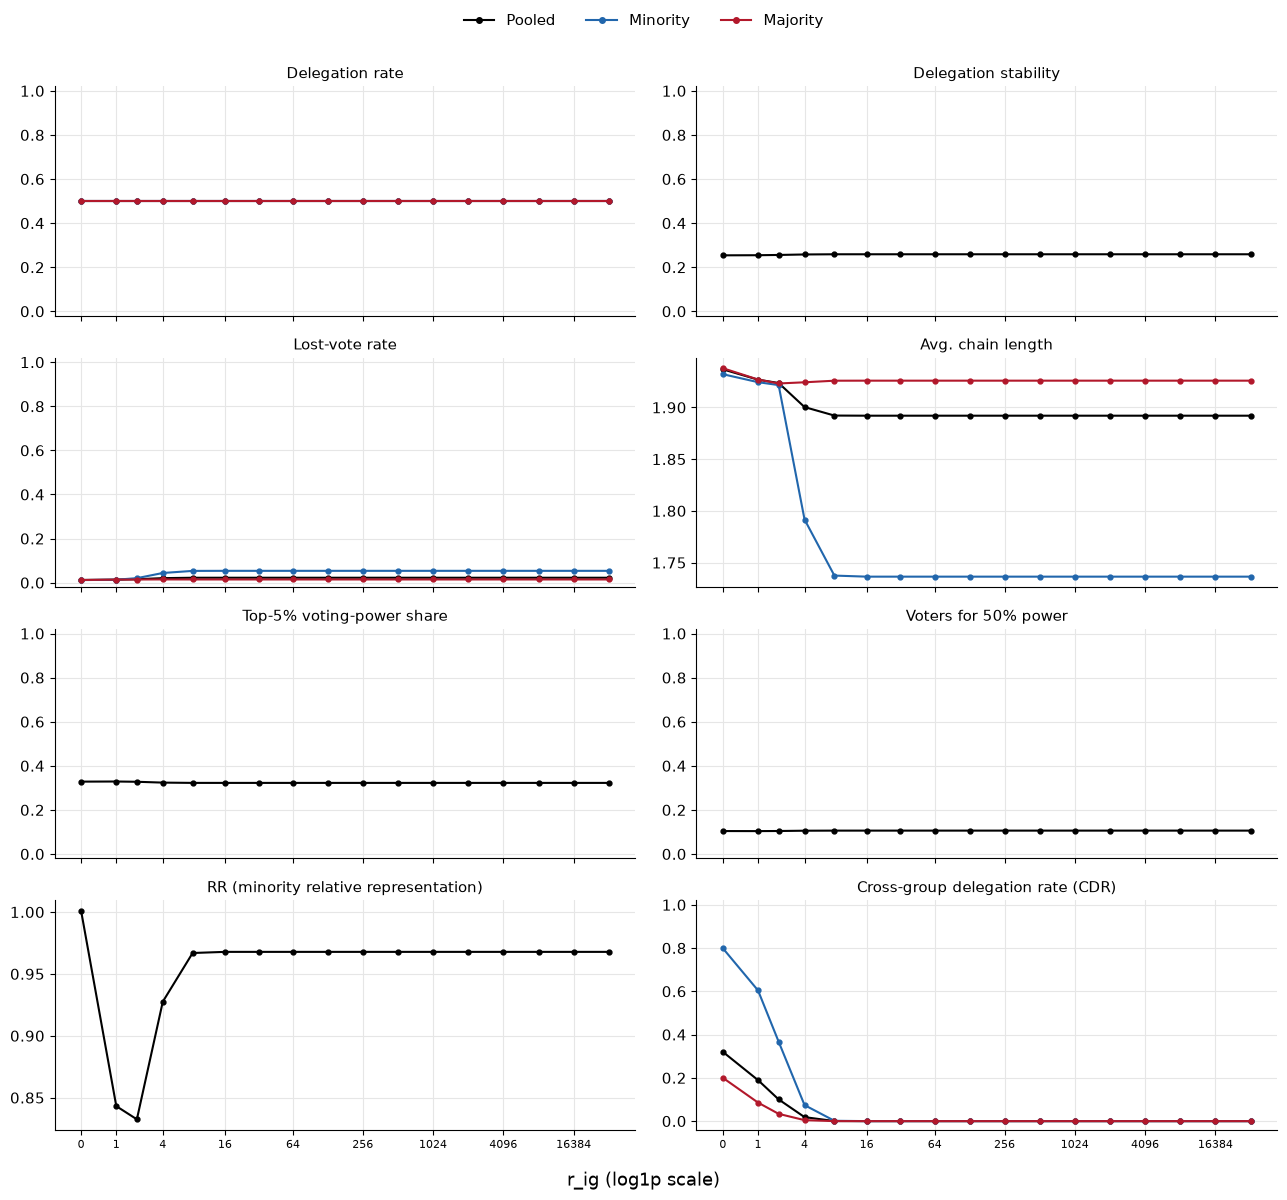

,r_ig,metric,mean_val,ci_lo,ci_hi,n_seeds,group
0,0,Delegation rate,0.500466,0.499051,0.501881,100.0,Pooled
1,0,Delegation stability,0.253968,0.252552,0.255384,100.0,Pooled
2,0,Lost-vote rate,0.012072,0.011363,0.012781,100.0,Pooled
3,0,Avg. chain length,1.936795,1.924793,1.948796,100.0,Pooled
4,0,Top-5% voting-power share,0.328288,0.326456,0.330120,100.0,Pooled
...,...,...,...,...,...,...,...
267,16384,Cross-group delegation rate (CDR),0.000000,0.000000,0.000000,100.0,Majority
268,32768,Delegation rate,0.500298,0.498716,0.501879,100.0,Majority
269,32768,Lost-vote rate,0.014515,0.013575,0.015455,100.0,Majority
270,32768,Avg. chain length,1.925854,1.912836,1.938871,100.0,Majority


In [3]:
LABELS = {
    "delegation_rate": "Delegation rate", "delegation_stability": "Delegation stability", "lost_vote_rate": "Lost-vote rate",
    "chain_length": "Avg. chain length", "top5_power_share": "Top-5% voting-power share", "share_50pct": "Voters for 50% power",
    "RR_m": "RR (minority relative representation)", "cross_group_dlg_rate": "Cross-group delegation rate (CDR)",
    "realised_assortativity": "Realised assortativity",
}
UNIT = {"Delegation stability", "Delegation rate", "Lost-vote rate", "Top-5% voting-power share", "Voters for 50% power",
        "Cross-group delegation rate (CDR)"}
METRICS_P2 = ["delegation_rate", "delegation_stability", "lost_vote_rate", "chain_length", "top5_power_share", "share_50pct",
              "RR_m", "cross_group_dlg_rate"]
GROUP_SPLIT = {"delegation_rate": ("minority_delegation_rate", "majority_delegation_rate"),
               "lost_vote_rate": ("minority_lost_vote_rate", "majority_lost_vote_rate"),
               "chain_length": ("minority_chain_length", "majority_chain_length"),
               "cross_group_dlg_rate": ("cdr_min_to_maj", "cdr_maj_to_min")}  # minority -> majority, majority -> minority


def with_groups(raw, keys, metrics, labels=LABELS):
    # pooled metrics plus their minority / majority versions where one exists, as one summary with a group column
    parts = [summarise(raw, keys, metrics, labels).assign(group="Pooled")]
    for group, i in (("Minority", 0), ("Majority", 1)):
        split = {m: cols[i] for m, cols in GROUP_SPLIT.items() if m in metrics}
        renamed = raw[keys + list(split.values())].rename(columns={col: m for m, col in split.items()})
        parts.append(summarise(renamed, keys, list(split), labels).assign(group=group))
    s = pd.concat(parts, ignore_index=True)
    s["metric"] = pd.Categorical(s["metric"].astype(str), categories=[labels[m] for m in metrics], ordered=True)
    return s


R_IG_MAX = [0] + [2**i for i in range(16)]
grid_rig = crossing(pd.DataFrame({"r_ig": R_IG_MAX}), seed=SEEDS).assign(**BASE, r_op=0.0, r_pw=0.0, r_tr=0.0)
grid_rig = grid_rig.assign(**condition_columns(["random"] * len(grid_rig)))
with timed("simulation: r_ig isolated"):
    rig_raw = cached("part2_rig_isolated", grid_rig, run_window_grid)

rig_summary = with_groups(rig_raw, ["r_ig"], METRICS_P2)
fig = group_facet_plot(rig_summary, "r_ig", "r_ig (log1p scale)", unit_metrics=UNIT, log1p=True)
out.figure(fig, F["rig"], "rig_isolated")
out.table(rig_summary, F["rig"], "rig_isolated")

Ceiling read off the plot: CDR has flattened out by r_ig = 8 (delegation rate is flat over the whole range, so it cannot anchor the % scale).

**Why the delegation rate stays at 0.5**

- Vote or delegate depends only on the best neighbour: every agent has same-group neighbours (at least 3) with $A = 1$, so $P_{self} = c = 0.5$ for every r_ig
- r_ig only changes *whom* an agent delegates to: CDR falls from 0.32 to 0

**Why the minority's chain length falls**

- Minority delegations stay among its ~12 same-group neighbours, so mutual delegations and cycles become likely: minority lost votes 1.2 % -> 5.4 %
- Long chains are the ones most likely to end in a cycle, so the remaining resolved chains are shorter (1.93 -> 1.74)

In [4]:
R_SAT_RIG, R_SAT_METRIC = 8, "cross_group_dlg_rate"
rig_pooled = rig_summary[rig_summary["group"] == "Pooled"]


def pct_to_r_rig(pct):
    # value-based inverse interpolation on the anchor curve, restricted to r_ig <= ceiling (R: pct_to_r_from_anchor_rig)
    sub = rig_pooled[(rig_pooled["metric"] == LABELS[R_SAT_METRIC]) & (rig_pooled["r_ig"] <= R_SAT_RIG)].sort_values("r_ig")
    y0, y_sat = sub["mean_val"].iloc[0], sub["mean_val"].iloc[-1]
    if np.isclose(y0, y_sat):
        return np.full(np.shape(pct), sub["r_ig"].iloc[0], dtype=float)
    by_val = sub.sort_values("mean_val")
    return np.interp(y0 + np.asarray(pct) / 100 * (y_sat - y0), by_val["mean_val"], by_val["r_ig"])


def r_from_pct_shared(pct):
    # all four r at the same % of their own saturated effect
    return dict(r_op=r_from_pct_p1("op", pct), r_pw=r_from_pct_p1("pw", pct), r_tr=r_from_pct_p1("tr", pct), r_ig=pct_to_r_rig(pct))


pct_table_rig = pd.DataFrame({"pct": range(0, 101, 10)})
pct_table_rig["r_ig"] = pct_to_r_rig(pct_table_rig["pct"]).round(3)
out.table(pct_table_rig, F["rig"], "pct_to_r_ig")
display(pct_table_rig)

,pct,r_ig
0,0,0.000
1,10,0.245
2,20,0.489
3,30,0.734
4,40,0.978
5,50,1.328
6,60,1.687
7,70,2.102
8,80,2.881
9,90,3.661


## 3. Homophily effects

| condition | opinions | network |
|---|---|---|
| random | uniform, independent of group | no shuffle |
| polarised | minority ~ U[0, 0.5), majority ~ U[0.5, 1) | no shuffle |
| homophilic | polarised | group-homophily shuffle |
| non-polarised-homophily | uniform | group-homophily shuffle |

**Group-homophily shuffle** (`liquid/groups.py`; R: `shuffle_group_homophily`)

The network topology remains fixed, and 20 % of agents are randomly assigned to the minority group. The algorithm repeatedly picks one minority agent $i$ and one majority agent $j$ that each have at least one neighbour from the other group, and proposes to swap them: $i$ and $j$ trade places, taking their group membership and opinion with them, so the edges stay the same but different agents sit on them.

The swap is scored by the change in the number of cross-group edges $E$ (edges between a minority and a majority agent):

$$\Delta E = E_{\mathrm{after}} - E_{\mathrm{before}}$$

- $\Delta E < 0$: the swap separates the groups more
- $\Delta E > 0$: the swap mixes them more

A proposed swap is accepted with probability

$$P(\mathrm{accept}) = \min\left(1,\ e^{-\Delta E\, t(s)}\right), \qquad t(s) = 0.5 \cdot 10^{\,s/S},$$

where $s$ is the current step and $S = 400\,000$ is the step budget.

- $\Delta E \le 0$: $e^{-\Delta E\, t} \ge 1$, so the swap is always accepted
- $\Delta E > 0$: accepted only by chance, with probability $e^{-\Delta E\, t}$
- $t(s)$ grows from 0.5 at the start to 5 at the end (factor 10 over the run), so **the later the step, the stricter the decision**: for $\Delta E = +1$ the acceptance probability is $e^{-0.5} \approx 0.61$ at the start, $e^{-1.58} \approx 0.21$ halfway and $e^{-5} \approx 0.007$ at the end
- Early on, swaps that briefly mix the groups are still allowed, which helps the search escape local dead ends; later almost only improving swaps get through (simulated annealing)

The algorithm stops when the target assortativity is reached (checked every 100 steps) or when the step budget is used up. The target **max** is set to 1, i.e. complete group separation. This may be unattainable for a given network, and the finite search does not guarantee that the highest attainable assortativity is found.

**Group assortativity** (`liquid/groups.py`; `igraph::assortativity` on the binary minority label): the correlation of the group label at the two ends of an edge. Let $x_i = 1$ for minority and $x_i = 0$ for majority agents, and count every edge from both ends. Then

$$r = \frac{\overline{x_u x_v} - \bar{x}^{\,2}}{\bar{x}\,(1 - \bar{x})}$$

- $\bar{x}$: share of edge ends at minority agents (≈ 0.2 at 20 % minority with similar degrees)
- $\overline{x_u x_v}$: share of edge ends whose edge connects two minority agents
- $\bar{x}^{\,2}$: what $\overline{x_u x_v}$ would be under random mixing, so the numerator measures the excess of minority-minority edges over chance
- $\bar{x}(1 - \bar{x})$: the variance of the label, scales $r$ so that complete separation gives exactly 1

Example with $\bar{x} = 0.2$: random mixing gives $\overline{x_u x_v} = 0.04$ and $r = 0$; complete separation gives $\overline{x_u x_v} = 0.2$ and $r = (0.2 - 0.04)/(0.2 \cdot 0.8) = 1$. Negative values mean fewer same-group edges than by chance.

In short: the shuffle reduces cross-group edges through increasingly strict probabilistic swaps, and $r$ measures how much more often agents are linked to their own group than chance would predict.

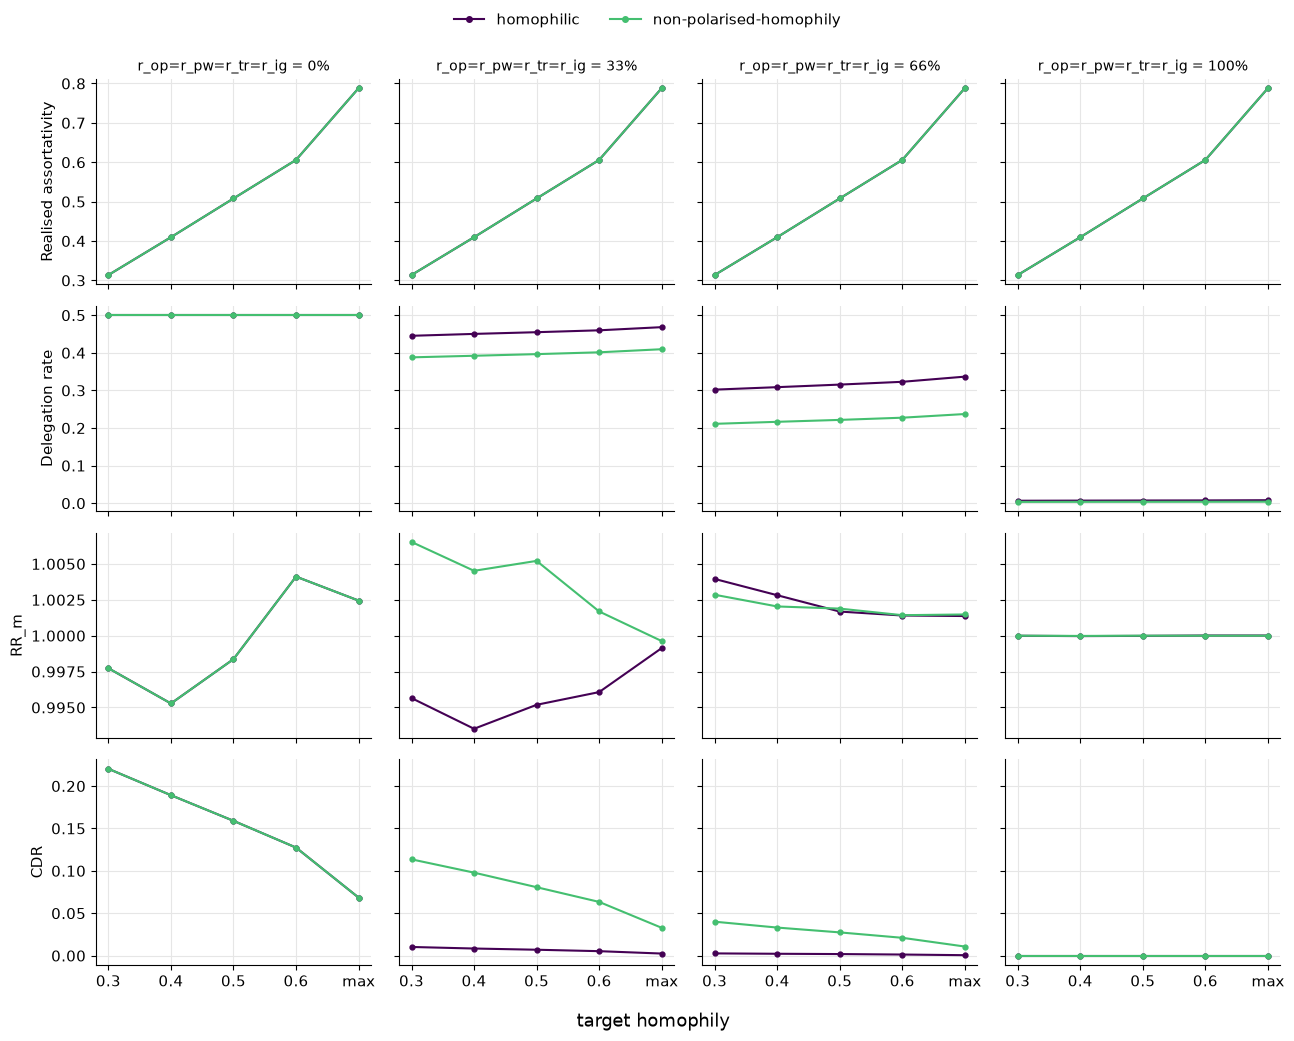

,mean,min,max,seeds
0,0.788,0.673,0.859,100


In [5]:
HOMOPHILY_LEVELS = [0.3, 0.4, 0.5, 0.6, 1.0]   # 1.0 = "max"
R_BG_PCT_LEVELS = [0, 33, 66, 100]              # r_op = r_pw = r_tr = r_ig, % of each one's own saturated effect
LEVEL_LABELS = ["0.3", "0.4", "0.5", "0.6", "max"]
BG_LABEL = lambda pct: f"r_op=r_pw=r_tr=r_ig = {pct}%"

grid_h = crossing(pd.DataFrame({"target_h": HOMOPHILY_LEVELS}), condition=["homophilic", "non-polarised-homophily"],
                  r_bg_pct=R_BG_PCT_LEVELS, seed=SEEDS)
grid_h = grid_h.assign(**BASE, **r_from_pct_shared(grid_h["r_bg_pct"]), **condition_columns(grid_h["condition"], grid_h["target_h"]))
with timed("simulation: homophily effects"):
    hom_raw = cached("part2_homophily_effects", grid_h, run_window_grid)

hom_raw["level"] = hom_raw["target_h"].map(dict(zip(HOMOPHILY_LEVELS, LEVEL_LABELS)))
hom_raw["background"] = hom_raw["r_bg_pct"].map(BG_LABEL)
hom_summary = summarise(hom_raw, ["condition", "level", "background"],
                        ["realised_assortativity", "delegation_rate", "RR_m", "cross_group_dlg_rate"],
                        {**LABELS, "RR_m": "RR_m", "cross_group_dlg_rate": "CDR"})
fig = metric_grid_plot(hom_summary, "level", "background", [BG_LABEL(p) for p in R_BG_PCT_LEVELS], "condition",
                       dict(zip(["homophilic", "non-polarised-homophily"], palette(["a", "b"], end=0.7).values())),
                       "target homophily", x_order=LEVEL_LABELS)
out.figure(fig, F["hom"], "homophily_effects")
out.table(hom_summary, F["hom"], "homophily_effects")

per_seed_max = hom_raw[hom_raw["level"] == "max"].drop_duplicates(["seed", "realised_assortativity"])["realised_assortativity"]
homophily_max = pd.DataFrame({"mean": [per_seed_max.mean()], "min": [per_seed_max.min()], "max": [per_seed_max.max()],
                              "seeds": [per_seed_max.size]}).round(3)
out.table(homophily_max, F["hom"], "max_assortativity")
display(homophily_max)

Chosen for RQ4/RQ5: **target homophily = max** (as long as CDR has not collapsed to 0 there).

In [6]:
CHOSEN_TARGET_HOMOPHILY = 1.0

## 4. Minority share

Sweep over 15-40 % in 5-point steps: (a) r_ig alone at 0/33/66/100 % of its saturated effect, r_op = r_pw = r_tr = 0; (b) all four r at the same %. Random condition.

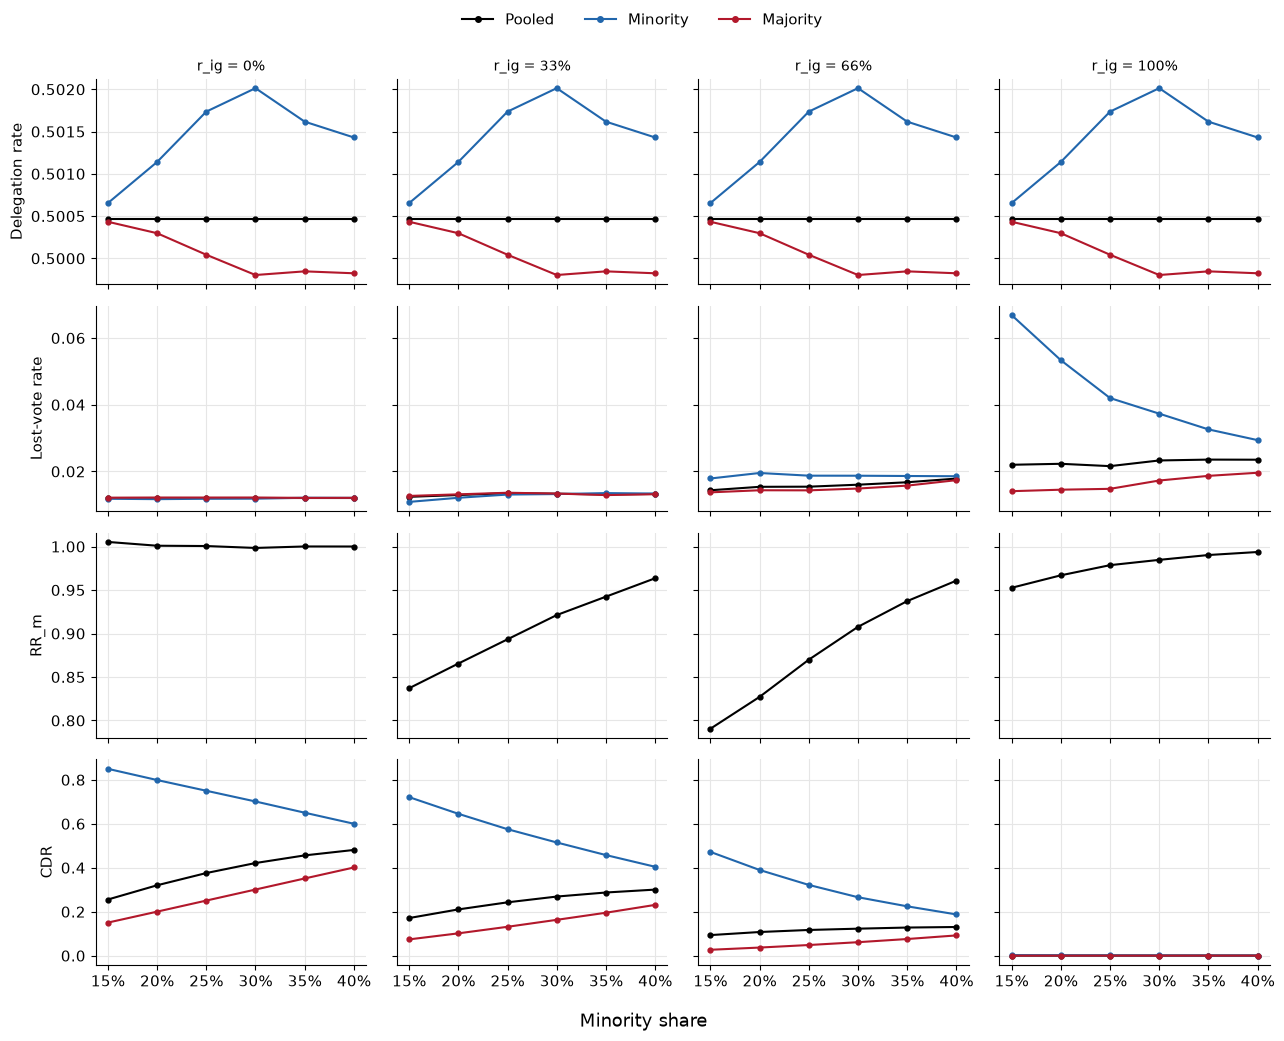

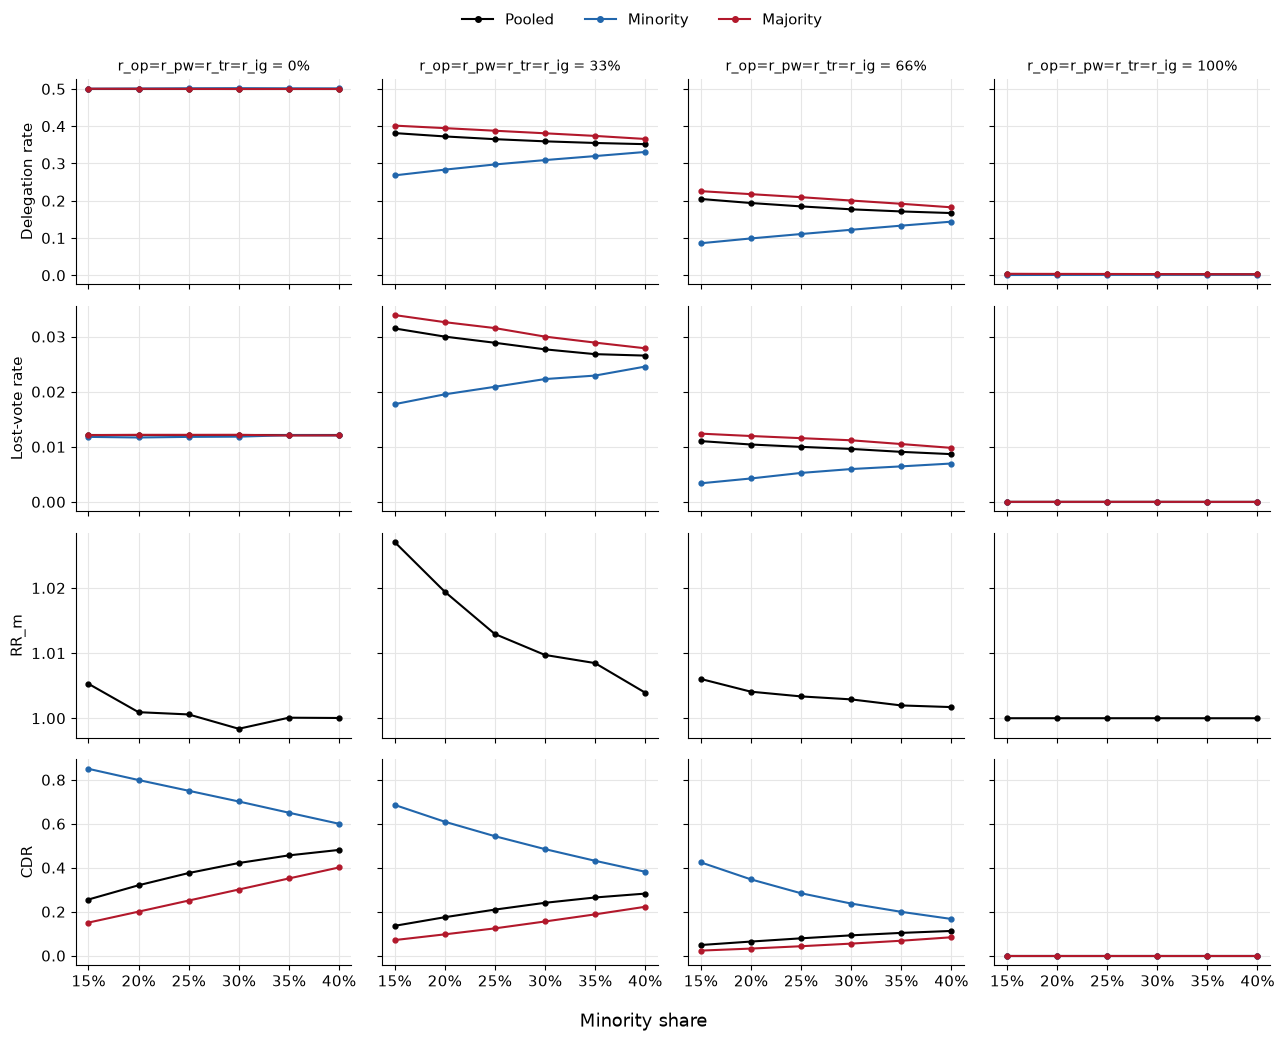

In [7]:
MINORITY_SHARE_LEVELS = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
SHARE_METRICS = ["delegation_rate", "lost_vote_rate", "RR_m", "cross_group_dlg_rate"]
SHARE_LABELS = {"RR_m": "RR_m", "cross_group_dlg_rate": "CDR"}
PCT_FMT = mticker.PercentFormatter(1.0, decimals=0)


def share_plot(raw, level_col, label, name):
    raw = raw.assign(panel=raw[level_col].map(label))
    s = with_groups(raw, ["minority_share", "panel"], SHARE_METRICS, {**LABELS, **SHARE_LABELS})
    fig = metric_grid_plot(s, "minority_share", "panel", [label(p) for p in sorted(raw[level_col].unique())], "group",
                           GROUP_COLORS, "Minority share", x_format=PCT_FMT)
    out.figure(fig, F["share"], name)
    out.table(s, F["share"], name)


R_IG_PCT_LEVELS_SHARE = [0, 33, 66, 100]
grid_s = crossing(pd.DataFrame({"minority_share": MINORITY_SHARE_LEVELS}), r_ig_pct=R_IG_PCT_LEVELS_SHARE, seed=SEEDS)
grid_s = grid_s.assign(**BASE, r_op=0.0, r_pw=0.0, r_tr=0.0, r_ig=pct_to_r_rig(grid_s["r_ig_pct"]), opinion_split=np.nan,
                       target_homophily=np.nan)
with timed("simulation: minority share, r_ig alone"):
    share_raw = cached("part2_minority_share", grid_s, run_window_grid)
share_plot(share_raw, "r_ig_pct", lambda p: f"r_ig = {p}%", "minority_share_rig")

grid_sb = crossing(pd.DataFrame({"minority_share": MINORITY_SHARE_LEVELS}), r_bg_pct=R_BG_PCT_LEVELS, seed=SEEDS)
grid_sb = grid_sb.assign(**BASE, **r_from_pct_shared(grid_sb["r_bg_pct"]), opinion_split=np.nan, target_homophily=np.nan)
with timed("simulation: minority share, all four r"):
    share_bg_raw = cached("part2_minority_share_bg", grid_sb, run_window_grid)
share_plot(share_bg_raw, "r_bg_pct", BG_LABEL, "minority_share_all_r")

Delegation rate, lost votes, RR_m and CDR behave smoothly over 15-40 %, so the minority share stays at **20 %** (about 200 minority agents at N = 1000).

## 5. Final calibrated values (Part II)

In [8]:
final = pd.DataFrame({
    "setting": ["minority share", "target homophily", "realised assortativity at max (mean over seeds)", "r_ig ceiling",
                "r_ig ceiling read off on", "K, T, n_v, lambda, c"],
    "value": [MINORITY_SHARE, "max", homophily_max["mean"].iloc[0], R_SAT_RIG, LABELS[R_SAT_METRIC], "carried over from Part I (Sec. 1)"],
})
out.table(final, F["final"], "final_values")
display(final)

,setting,value
0,minority share,0.2
1,target homophily,max
2,realised assortativity at max (mean over seeds),0.788
3,r_ig ceiling,8
4,r_ig ceiling read off on,Cross-group delegation rate (CDR)
5,"K, T, n_v, lambda, c",carried over from Part I (Sec. 1)
